# Comparación por grupo de dirección

Contrasto la hipótesis: en todos los géneros con al menos 500 películas
de dirección conocida (100 en el nivel de películas con al menos 100
votos), las mujeres y personas no binarias dirigen menos del 50 %.

Esta hipótesis la formulé después de explorar los datos, no antes. Mi
hipótesis inicial incluía además la evolución temporal y el género que
más dirigen las mujeres (ver informe). Por eso se presenta como una
hipótesis revisada y no como una predicción previa.

Trabajo con las películas de dirección conocida (Mujeres y personas no
binarias, Hombres y Mixto). «No identificado» y las descartadas se
muestran siempre aparte.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import find_dotenv

raiz = Path(find_dotenv(usecwd=True)).resolve().parent
carpeta_proc = raiz / "src" / "data" / "processed"
carpeta_fig = raiz / "figuras"
carpeta_fig.mkdir(exist_ok=True)

# Formato español (coma decimal, punto de miles) y colores comunes
def coma(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

COLOR_MUJERES = "#c44e52"     # mujeres y personas no binarias
COLOR_HOMBRES = "#4c72b0"
COLOR_MIXTO = "#8172b3"
COLOR_NEUTRO = "#bbbbbb"      # lo que no entra en la comparación
COLOR_REFERENCIA = "#333333"  # líneas de referencia (50 %)
GENERO_COLOR = {"Drama": "#8c564b", "Documental": "#e69f00",
                "Comedia": "#2ca02c", "Terror": "#7b3294"}

df_todas = pd.read_pickle(carpeta_proc / "peliculas_todas_con_grupo.pkl")
df = pd.read_pickle(carpeta_proc / "peliculas_con_direccion.pkl")

generos = {
    28: "Acción", 12: "Aventura", 16: "Animación", 35: "Comedia",
    80: "Crimen", 99: "Documental", 18: "Drama", 10751: "Familia",
    14: "Fantasía", 36: "Historia", 27: "Terror", 10402: "Música",
    9648: "Misterio", 10749: "Romance", 878: "Ciencia ficción",
    10770: "Película de TV", 53: "Suspense", 10752: "Bélica", 37: "Western",
}
ETIQ = {"Mujeres": "Mujeres y personas no binarias"}

conocida = df[df["grupo_direccion"].isin(["Mujeres", "Hombres", "Mixto"])].copy()

g = conocida[["id", "anio_estreno", "genre_ids", "grupo_direccion", "vote_count"]].copy()
g["genre_ids"] = g["genre_ids"].apply(lambda x: x if len(x) > 0 else [None])
g = g.explode("genre_ids")
g["genero"] = g["genre_ids"].map(generos).fillna("Sin género")

def miles(v):
    return f"{int(v):,}".replace(",", ".")

print("Películas totales:", miles(len(df_todas)))
print("Base del análisis:", miles(len(df)))
print("Dirección conocida:", miles(len(conocida)))
print(conocida["grupo_direccion"].value_counts(normalize=True).mul(100).round(1))

Películas totales: 681.868
Base del análisis: 602.451
Dirección conocida: 279.681
grupo_direccion
Hombres    78.3
Mujeres    20.2
Mixto       1.5
Name: proportion, dtype: float64


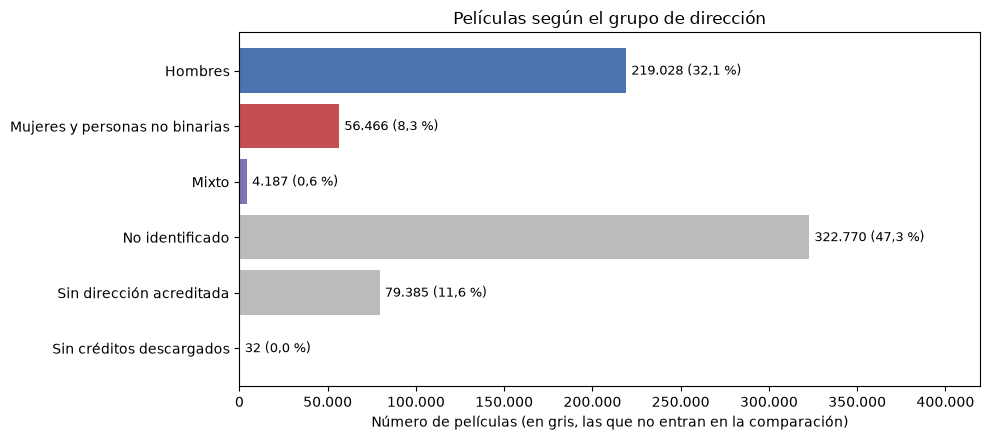

In [15]:
orden = ["Hombres", "Mujeres", "Mixto", "No identificado",
         "Sin dirección acreditada", "Sin créditos descargados"]
tam = df_todas["grupo_direccion"].value_counts().reindex(orden)

fig, ax = plt.subplots(figsize=(10, 4.5))
etiquetas = [ETIQ.get(x, x) for x in orden][::-1]
valores = tam.values[::-1]
COLORES_GRUPO = {"Hombres": COLOR_HOMBRES, "Mujeres y personas no binarias": COLOR_MUJERES,
                 "Mixto": COLOR_MIXTO}
colores = [COLORES_GRUPO.get(e, COLOR_NEUTRO) for e in etiquetas]
ax.barh(etiquetas, valores, color=colores)
for i, v in enumerate(valores):
    pct = f"{v / len(df_todas) * 100:.1f}".replace(".", ",")
    ax.text(v + 3000, i, f"{miles(v)} ({pct} %)", va="center", fontsize=9)
ax.set_xlim(0, valores.max() * 1.3)
ax.set_title("Películas según el grupo de dirección")
ax.xaxis.set_major_formatter(lambda x, _: miles(x))
ax.set_xlabel("Número de películas (en gris, las que no entran en la comparación)")
plt.tight_layout()
fig.savefig(carpeta_fig / "05_grupos_direccion.png", dpi=200)
plt.show()

Solo el 41 % de las películas tiene una dirección con género conocido
(279.681 de 681.868). El grupo más grande es «No identificado» (47,3 %),
seguido de Hombres (32,1 %). Mujeres y personas no binarias son el
8,3 % del total y el 20,2 % de las películas con género conocido.


=== Todas las películas | películas de dirección conocida: 279.681 | % mujeres global: 20.2 ===
Géneros con muestra insuficiente (no se interpretan): []
Géneros con % mujeres >= 50: []
Géneros con % alguna mujer >= 50: []


,n,n_mujeres,n_mixto,pct_mujeres,pct_alguna,ic95
genero,,,,,,
Documental,57089,15257,1642,26.7,29.6,0.4
Animación,15961,4100,399,25.7,28.2,0.7
Drama,90866,18074,1054,19.9,21.1,0.3
Romance,22332,4226,220,18.9,19.9,0.5
Película de TV,12124,2238,128,18.5,19.5,0.7
Familia,10183,1641,189,16.1,18.0,0.7
Fantasía,9981,1522,172,15.2,17.0,0.7
Música,10784,1591,224,14.8,16.8,0.7
Comedia,52394,7547,682,14.4,15.7,0.3


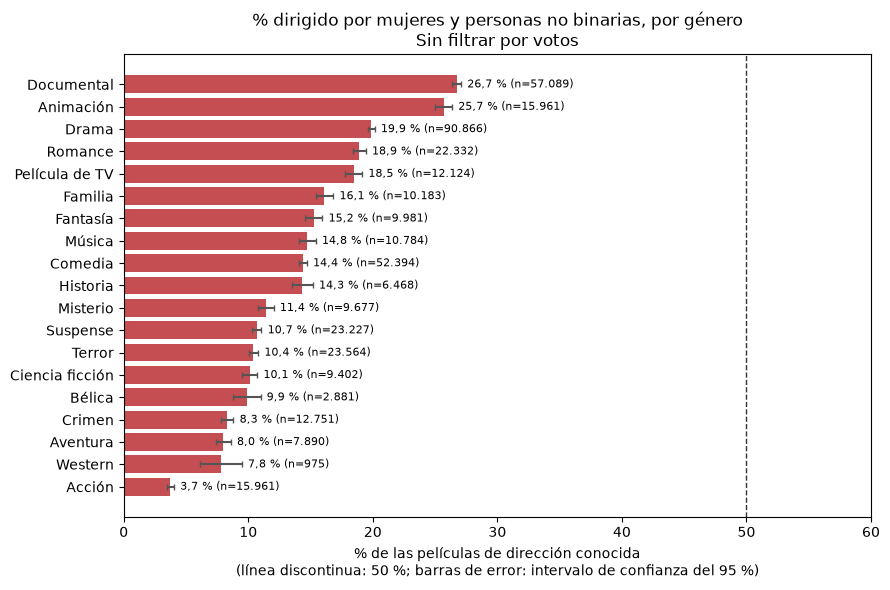


=== Con al menos 1 voto | películas de dirección conocida: 149.699 | % mujeres global: 16.6 ===
Géneros con muestra insuficiente (no se interpretan): []
Géneros con % mujeres >= 50: []
Géneros con % alguna mujer >= 50: []


,n,n_mujeres,n_mixto,pct_mujeres,pct_alguna,ic95
genero,,,,,,
Documental,24775,5751,843,23.2,26.6,0.5
Película de TV,10257,1912,89,18.6,19.5,0.8
Romance,17249,3170,158,18.4,19.3,0.6
Drama,59142,10837,700,18.3,19.5,0.3
Animación,8244,1372,248,16.6,19.7,0.8
Familia,7718,1105,149,14.3,16.2,0.8
Historia,4705,671,96,14.3,16.3,1.0
Comedia,37173,5060,477,13.6,14.9,0.3
Música,5988,807,147,13.5,15.9,0.9


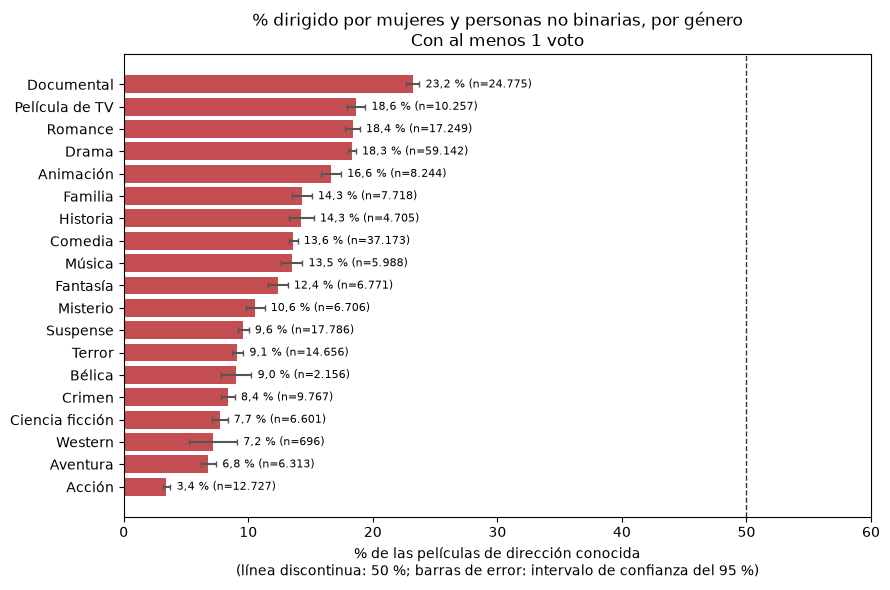


=== Con al menos 100 votos | películas de dirección conocida: 15.501 | % mujeres global: 10.7 ===
Géneros con muestra insuficiente (no se interpretan): []
Géneros con % mujeres >= 50: []
Géneros con % alguna mujer >= 50: []


,n,n_mujeres,n_mixto,pct_mujeres,pct_alguna,ic95
genero,,,,,,
Romance,2403,456.0,23.0,19.0,19.9,1.6
Documental,545,97.0,41.0,17.8,25.3,3.2
Música,465,71.0,17.0,15.3,18.9,3.3
Drama,6941,1013.0,69.0,14.6,15.6,0.8
Comedia,5509,601.0,97.0,10.9,12.7,0.8
Película de TV,472,51.0,5.0,10.8,11.9,2.8
Historia,753,81.0,7.0,10.8,11.7,2.2
Misterio,1321,110.0,13.0,8.3,9.3,1.5
Familia,1479,116.0,43.0,7.8,10.8,1.4


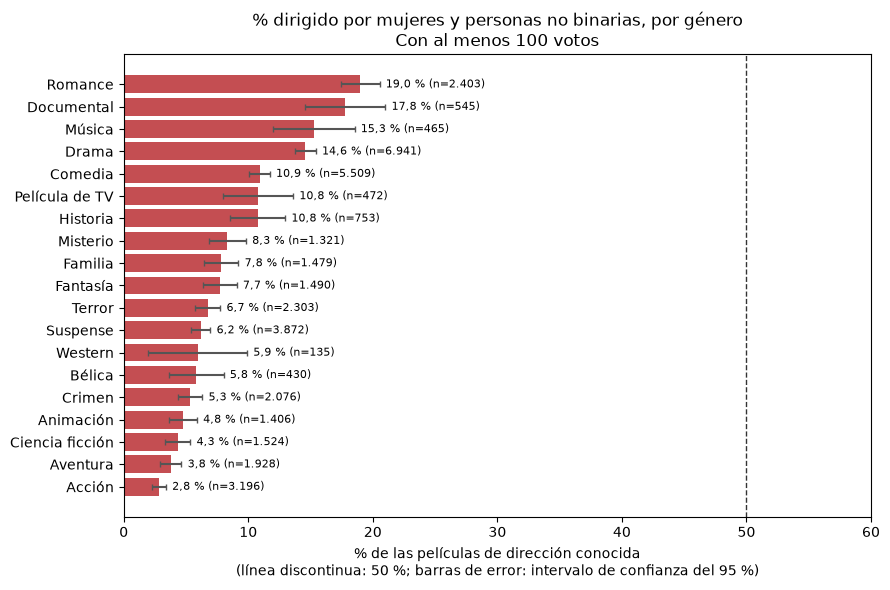

In [16]:
NIVELES = {
    "Todas las películas": (0, 500),
    "Con al menos 1 voto": (1, 500),
    "Con al menos 100 votos": (100, 100),
}

TITULOS_NIVEL = {"Todas las películas": "Sin filtrar por votos",
                 "Con al menos 1 voto": "Con al menos 1 voto",
                 "Con al menos 100 votos": "Con al menos 100 votos"}
CLAVES_FIG = {"Todas las películas": "todas", "Con al menos 1 voto": "1voto",
              "Con al menos 100 votos": "100votos"}

def presencia(vmin):
    s = g[g["vote_count"] >= vmin]
    t = s.groupby("genero")["id"].nunique().rename("n")
    m = s[s["grupo_direccion"] == "Mujeres"].groupby("genero")["id"].nunique().rename("n_mujeres")
    x = s[s["grupo_direccion"] == "Mixto"].groupby("genero")["id"].nunique().rename("n_mixto")
    r = pd.concat([t, m, x], axis=1).fillna(0)
    r["pct_mujeres"] = r["n_mujeres"] / r["n"] * 100
    r["pct_alguna"] = (r["n_mujeres"] + r["n_mixto"]) / r["n"] * 100
    p = r["pct_mujeres"] / 100
    r["ic95"] = 1.96 * np.sqrt(p * (1 - p) / r["n"]) * 100
    return r

resultados = {}
for i, (nombre, (vmin, umbral)) in enumerate(NIVELES.items(), start=1):
    r = presencia(vmin)
    resultados[nombre] = r
    total = conocida[conocida["vote_count"] >= vmin]
    print(f"\n=== {nombre} | películas de dirección conocida: {miles(len(total))} "
          f"| % mujeres global: {(total['grupo_direccion'] == 'Mujeres').mean() * 100:.1f} ===")

    valido = r.drop(index="Sin género", errors="ignore")
    ok = valido[valido["n"] >= umbral].sort_values("pct_mujeres")
    peq = valido[valido["n"] < umbral]
    print("Géneros con muestra insuficiente (no se interpretan):", list(peq.index))
    print("Géneros con % mujeres >= 50:", list(ok[ok["pct_mujeres"] >= 50].index))
    print("Géneros con % alguna mujer >= 50:", list(ok[ok["pct_alguna"] >= 50].index))
    display(ok.sort_values("pct_mujeres", ascending=False).round(1))

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(ok.index, ok["pct_mujeres"], xerr=ok["ic95"], color=COLOR_MUJERES,
            error_kw={"ecolor": "#555555", "capsize": 2})
    ax.axvline(50, color=COLOR_REFERENCIA, linestyle="--", linewidth=1)
    for j, (pct, n) in enumerate(zip(ok["pct_mujeres"], ok["n"])):
        ax.text(pct + ok["ic95"].iloc[j] + 0.5, j,
                f"{coma(pct, 1)} % (n={miles(n)})", va="center", fontsize=8)
    ax.set_xlim(0, 60)
    ax.set_title(f"% dirigido por mujeres y personas no binarias, por género\n{TITULOS_NIVEL[nombre]}")
    ax.set_xlabel("% de las películas de dirección conocida\n"
                  "(línea discontinua: 50 %; barras de error: intervalo de confianza del 95 %)")
    plt.tight_layout()
    fig.savefig(carpeta_fig / f"06{'abc'[i-1]}_mujeres_por_genero_{CLAVES_FIG[nombre]}.png", dpi=200)
    plt.show()

En ningún género las mujeres y personas no binarias dirigen la mitad
de las películas, en ninguno de los tres niveles de visibilidad. Tampoco
llegan al 50 % si se cuentan también las películas mixtas: el máximo
es el 29,6 % en documental con todas las películas.

Con todas las películas, el máximo es documental (26,7 %) y el mínimo
acción (3,7 %). Con al menos 1 voto, el máximo sigue siendo documental
(23,2 %) y el mínimo acción (3,4 %). Con al menos 100 votos, el máximo
es romance (19,0 %) y el mínimo acción (2,8 %).

El porcentaje global baja al exigir votos: 20,2 % con todas las
películas, 16,6 % con al menos 1 voto y 10,7 % con al menos 100. Las
películas dirigidas por mujeres y personas no binarias están menos
representadas entre las que tienen más votos.

La hipótesis se cumple, pero era un resultado esperable: con un 20 %
global, que un género superase el 50 % habría exigido una diferencia
enorme respecto a la media. Lo más informativo son las diferencias
entre géneros y la evolución en el tiempo, que se analizan después.

Las barras de error de los gráficos son intervalos de confianza
aproximados al 95 % para una proporción. Son estrechos cuando hay
muchas películas y más anchos en el nivel de 100 votos, donde hay
menos. No incluyen el posible sesgo por las películas descartadas o de
dirección no identificada, que se discute más adelante.

Género más frecuente, mujeres y no binarias: Drama
Género más frecuente, hombres: Drama
Mayor ventaja relativa de mujeres (pp): Documental 8.7


,Mujeres y personas no binarias,Hombres,dif_pp
genero,,,
Documental,27.0,18.3,8.7
Sin género,18.9,14.1,4.8
Animación,7.3,5.2,2.0
Western,0.1,0.4,-0.3
Película de TV,4.0,4.5,-0.5
Bélica,0.5,1.2,-0.7
Romance,7.5,8.2,-0.7
Drama,32.0,32.8,-0.7
Historia,1.6,2.5,-0.8


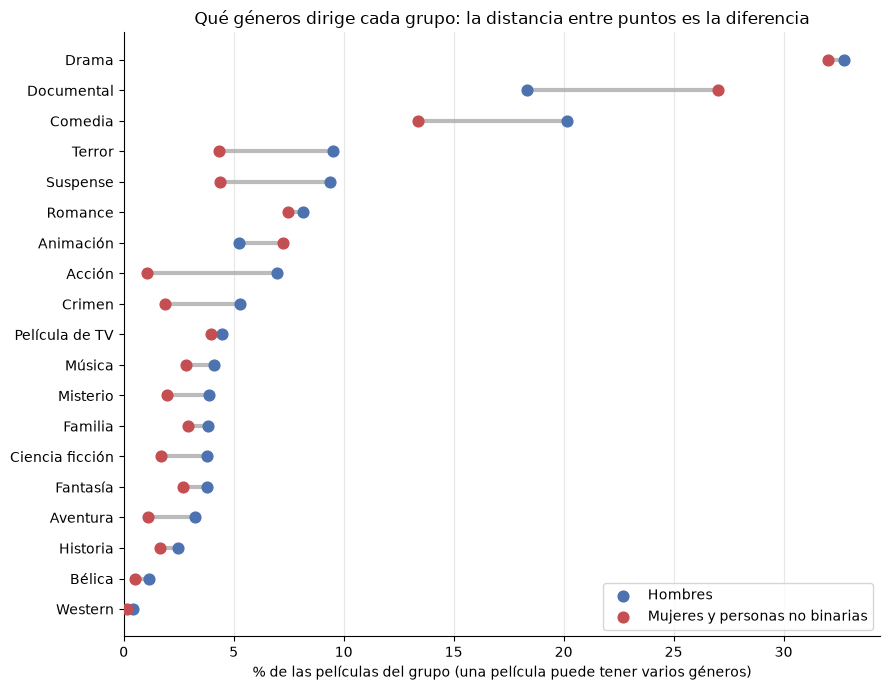

In [17]:
den = conocida.groupby("grupo_direccion")["id"].nunique()
cnt = g.groupby(["grupo_direccion", "genero"])["id"].nunique().unstack(0).fillna(0)
comp = pd.DataFrame({
    "Mujeres y personas no binarias": cnt["Mujeres"] / den["Mujeres"] * 100,
    "Hombres": cnt["Hombres"] / den["Hombres"] * 100,
})
comp["dif_pp"] = comp["Mujeres y personas no binarias"] - comp["Hombres"]
comp = comp.sort_values("Mujeres y personas no binarias")

print("Género más frecuente, mujeres y no binarias:", comp["Mujeres y personas no binarias"].idxmax())
print("Género más frecuente, hombres:", comp["Hombres"].idxmax())
print("Mayor ventaja relativa de mujeres (pp):", comp["dif_pp"].idxmax(), round(comp["dif_pp"].max(), 1))
display(comp.sort_values("dif_pp", ascending=False).round(1))

# Un punto rojo (ellas) y uno azul (ellos) por género, unidos por una línea:
# la distancia entre los dos puntos es la diferencia entre grupos
M, H = "Mujeres y personas no binarias", "Hombres"
# «Sin género» no es un género (son películas sin ninguno asignado): sale en la
# tabla de arriba, pero no en la gráfica
orden = (comp.drop(index="Sin género", errors="ignore")
         .assign(mayor=lambda d: d[[M, H]].max(axis=1)).sort_values("mayor"))
y = np.arange(len(orden))

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(y, orden[M], orden[H], color=COLOR_NEUTRO, linewidth=3, zorder=1)
ax.scatter(orden[H], y, color=COLOR_HOMBRES, s=60, zorder=2, label="Hombres")
ax.scatter(orden[M], y, color=COLOR_MUJERES, s=60, zorder=3, label=M)
ax.set_yticks(y)
ax.set_yticklabels(orden.index)
ax.set_title("Qué géneros dirige cada grupo: la distancia entre puntos es la diferencia")
ax.set_xlabel("% de las películas del grupo (una película puede tener varios géneros)")
ax.set_xlim(0, None)
ax.xaxis.set_major_formatter(lambda x, _: coma(x, 0))
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(carpeta_fig / "07_generos_por_grupo.png", dpi=200)
plt.show()

En la gráfica, cada género tiene un punto rojo (peso del género en la
filmografía de las mujeres y personas no binarias) y uno azul (peso en la
de los hombres). La línea gris que los une es la diferencia: cuanto más
larga, más distinto es el peso del género entre ambos grupos.

El drama es el género más frecuente en ambos grupos (32,0 % entre
mujeres y personas no binarias, 32,8 % entre hombres): sus dos puntos casi
coinciden, por lo que no distingue a las directoras. La mayor diferencia a
favor de ellas es el documental (+8,7 puntos). Los hombres pesan más en
comedia, acción, terror y suspense.

No represento «Sin género» (películas a las que TMDB no asigna ningún género), porque no es un género; sí aparece en la tabla de arriba.

Todas las películas: pendiente +0.54 pp/año | 2000-2004: 13.5 % | 2021-2025: 24.2 %
Con al menos 1 voto: pendiente +0.48 pp/año | 2000-2004: 12.0 % | 2021-2025: 21.3 %
Con al menos 100 votos: pendiente +0.47 pp/año | 2000-2004: 6.4 % | 2021-2025: 16.2 %


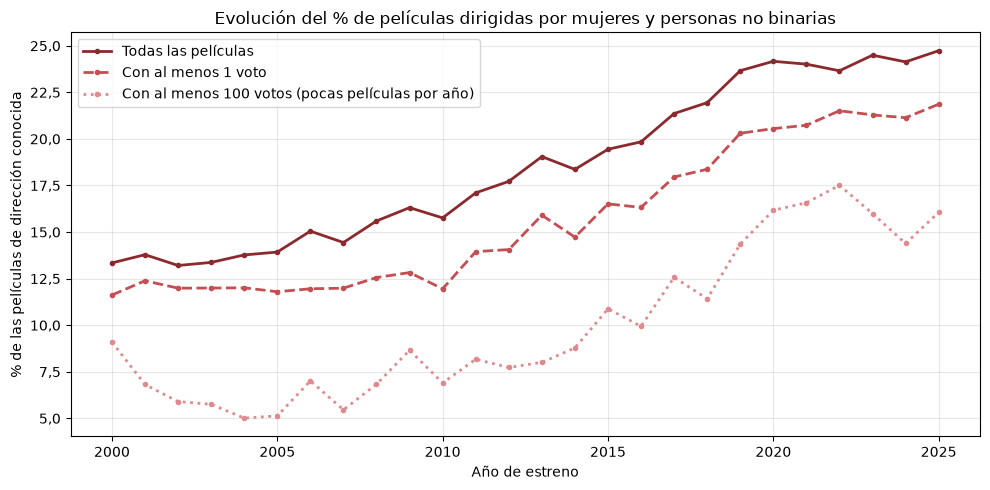

anio_estreno,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Todas las películas,5006,5266,5452,5699,6041,6362,7110,7431,7925,8081,...,11848,13126,13870,14668,14110,15183,16396,17726,19167,19688
Con al menos 1 voto,3615,3770,3912,3968,4172,4247,4274,4371,4491,4709,...,6702,7323,7501,7703,6690,7172,8000,8112,7669,7080
Con al menos 100 votos,286,308,339,365,399,409,499,513,556,566,...,815,875,902,836,637,718,731,669,563,467


In [18]:
def serie(vmin):
    s = conocida[conocida["vote_count"] >= vmin]
    t = s.groupby("anio_estreno").size()
    m = s[s["grupo_direccion"] == "Mujeres"].groupby("anio_estreno").size().reindex(t.index, fill_value=0)
    return pd.DataFrame({"n": t, "n_mujeres": m, "pct": m / t * 100})

series = {nombre: serie(vmin) for nombre, (vmin, _) in NIVELES.items()}

# Tres tonos del color de mujeres: del más oscuro (todas) al más claro (100 votos)
ESTILO_NIVEL = {
    "Todas las películas": dict(color="#8b2a2e", linestyle="-"),
    "Con al menos 1 voto": dict(color=COLOR_MUJERES, linestyle="--"),
    "Con al menos 100 votos": dict(color="#e08a8e", linestyle=":"),
}
ETIQ_NIVEL = {
    "Todas las películas": "Todas las películas",
    "Con al menos 1 voto": "Con al menos 1 voto",
    "Con al menos 100 votos": "Con al menos 100 votos (pocas películas por año)",
}

fig, ax = plt.subplots(figsize=(10, 5))
for nombre, s in series.items():
    ax.plot(s.index, s["pct"], marker="o", markersize=3, linewidth=2,
            label=ETIQ_NIVEL[nombre], **ESTILO_NIVEL[nombre])
    pend = np.polyfit(s.index, s["pct"], 1)[0]
    a = s.loc[2000:2004]; b = s.loc[2021:2025]
    print(f"{nombre}: pendiente {pend:+.2f} pp/año | 2000-2004: "
          f"{a['n_mujeres'].sum() / a['n'].sum() * 100:.1f} % | 2021-2025: "
          f"{b['n_mujeres'].sum() / b['n'].sum() * 100:.1f} %")
ax.set_title("Evolución del % de películas dirigidas por mujeres y personas no binarias")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("% de las películas de dirección conocida")
ax.yaxis.set_major_formatter(lambda y, _: coma(y, 1))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(carpeta_fig / "08_evolucion_mujeres.png", dpi=200)
plt.show()

display(pd.DataFrame({n: s["n"] for n, s in series.items()}).T)

El porcentaje aumenta entre 2000 y 2025 en los tres niveles, con una
pendiente de entre +0,47 y +0,54 puntos porcentuales por año. En el
conjunto completo pasa del 13,5 % (2000-2004) al 24,2 % (2021-2025).
Al restringir a películas con votos el aumento se mantiene, aunque
con menor porcentaje.

In [19]:
# Correlación entre el año y el % de mujeres, en cada nivel de votos
# Spearman = Pearson calculado sobre los puestos (rangos) en lugar de los valores
filas_corr = []
for nombre, s in series.items():
    filas_corr.append({
        "Nivel": nombre,
        "Pearson": round(np.corrcoef(s.index, s["pct"])[0, 1], 2),
        "Spearman": round(np.corrcoef(s.index, s["pct"].rank())[0, 1], 2),
        "Años": len(s),
    })
display(pd.DataFrame(filas_corr).set_index("Nivel"))


,Pearson,Spearman,Años
Nivel,,,
Todas las películas,0.98,0.98,26
Con al menos 1 voto,0.95,0.94,26
Con al menos 100 votos,0.89,0.87,26


La correlación mide si el porcentaje de mujeres sube de forma sostenida
con el año: vale entre -1 y 1, y un valor cercano a 1 indica que, a más
años, más porcentaje. Calculo dos versiones: Pearson (relación en línea
recta) y Spearman (solo mira si el orden coincide, sin suponer una recta).

Es un complemento de la pendiente, que dice cuánto sube cada año. Con solo
26 años seguidos, y cada año parecido al anterior, no la interpreto como una
prueba estadística, sino como una forma de resumir lo que ya se ve en la gráfica.

### Mujeres frente a hombres: ¿crece el porcentaje solo porque hay más películas?

El porcentaje de mujeres se calcula sobre las películas de dirección conocida, por lo que ya tiene en cuenta que el número total de películas crece. Aun así, comparo directamente el número de películas dirigidas por mujeres y por hombres, y calculo cuántas películas dirigidas por mujeres y personas no binarias hay por cada 100 dirigidas por hombres. No incluyo las películas mixtas.

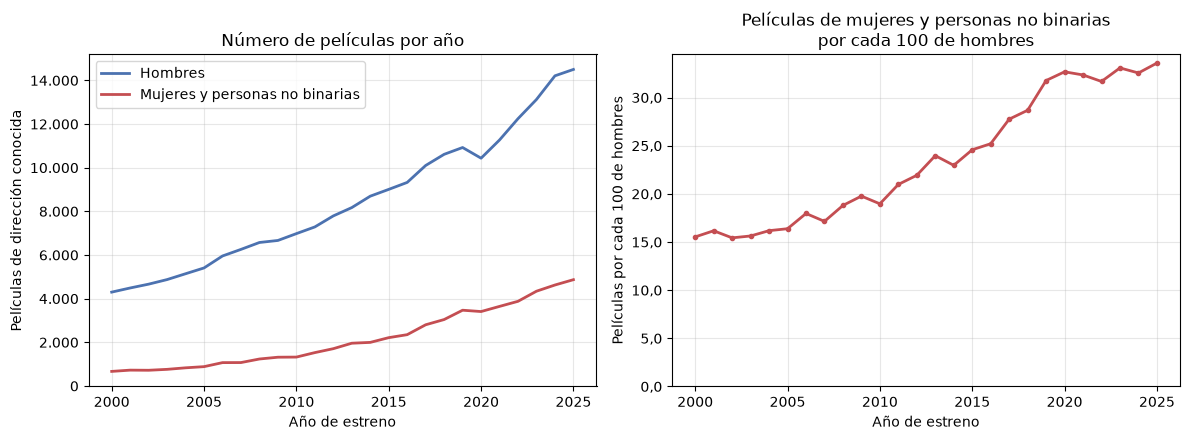

2000-2004: mujeres 3708 | hombres 23472 | por cada 100 de hombres: 15.8
2021-2025: mujeres 21363 | hombres 65356 | por cada 100 de hombres: 32.7
Películas de mujeres: x5.8 | de hombres: x2.8


In [20]:
# Mujeres frente a hombres, año a año (películas de dirección conocida)
hm = (conocida[conocida["grupo_direccion"].isin(["Mujeres", "Hombres"])]
      .groupby(["anio_estreno", "grupo_direccion"]).size().unstack())
hm["por_100"] = hm["Mujeres"] / hm["Hombres"] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(hm.index, hm["Hombres"], color=COLOR_HOMBRES, linewidth=2, label="Hombres")
ax1.plot(hm.index, hm["Mujeres"], color=COLOR_MUJERES, linewidth=2,
         label="Mujeres y personas no binarias")
ax1.set_title("Número de películas por año")
ax1.set_xlabel("Año de estreno")
ax1.set_ylabel("Películas de dirección conocida")
ax1.yaxis.set_major_formatter(lambda y, _: miles(y))
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(hm.index, hm["por_100"], color=COLOR_MUJERES, linewidth=2, marker="o", markersize=3)
ax2.set_title("Películas de mujeres y personas no binarias\npor cada 100 de hombres")
ax2.set_xlabel("Año de estreno")
ax2.set_ylabel("Películas por cada 100 de hombres")
ax2.set_ylim(0, None)
ax2.yaxis.set_major_formatter(lambda y, _: coma(y, 1))
ax2.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(carpeta_fig / "11_mujeres_frente_a_hombres.png", dpi=200)
plt.show()

# Resumen por periodos
a = hm.loc[2000:2004].sum()
b = hm.loc[2021:2025].sum()
for nombre, p in [("2000-2004", a), ("2021-2025", b)]:
    print(f"{nombre}: mujeres {int(p['Mujeres'])} | hombres {int(p['Hombres'])} | "
          f"por cada 100 de hombres: {p['Mujeres'] / p['Hombres'] * 100:.1f}")
print(f"Películas de mujeres: x{b['Mujeres'] / a['Mujeres']:.1f} | "
      f"de hombres: x{b['Hombres'] / a['Hombres']:.1f}")

Entre 2000-2004 y 2021-2025, las películas dirigidas por mujeres y personas no binarias pasan de 3.708 a 21.363 (se multiplican por 5,8), mientras que las dirigidas por hombres pasan de 23.472 a 65.356 (se multiplican por 2,8). Por cada 100 películas dirigidas por hombres, había 15,8 dirigidas por mujeres y personas no binarias en 2000-2004 y hay 32,7 en 2021-2025.

Por tanto, el aumento de la presencia de mujeres no se explica solo porque se registren más películas: sus películas crecen más rápido que las de los hombres. Esta comparación solo incluye las películas con el género de la dirección conocido, así que no descarta que parte del cambio se deba a cómo TMDB registra ese dato (véanse las limitaciones).

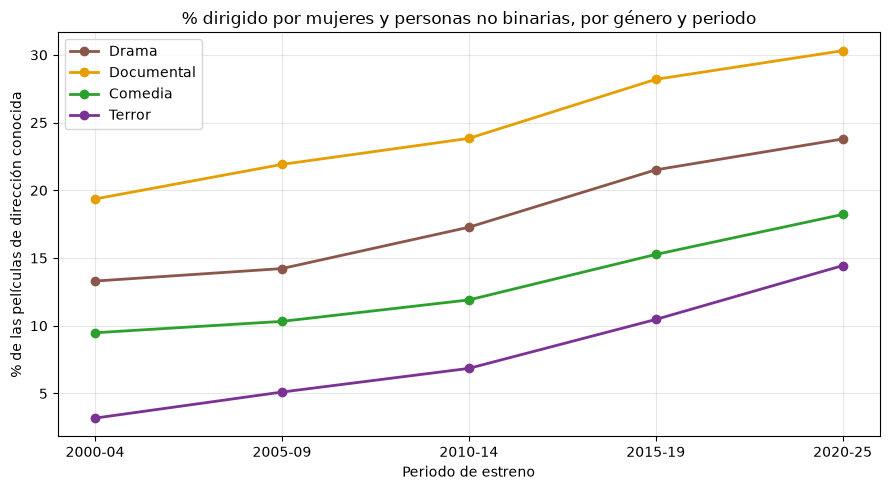

In [21]:
bins = [1999, 2004, 2009, 2014, 2019, 2025]
etq = ["2000-04", "2005-09", "2010-14", "2015-19", "2020-25"]
g["periodo"] = pd.cut(g["anio_estreno"], bins=bins, labels=etq)

top = ["Drama", "Documental", "Comedia", "Terror"]
fig, ax = plt.subplots(figsize=(9, 5))
for gen in top:
    s = g[g["genero"] == gen]
    t = s.groupby("periodo", observed=True)["id"].nunique()
    m = s[s["grupo_direccion"] == "Mujeres"].groupby("periodo", observed=True)["id"].nunique().reindex(t.index, fill_value=0)
    ax.plot(etq, (m / t * 100).reindex(etq), marker="o", linewidth=2,
            color=GENERO_COLOR.get(gen), label=gen)
ax.set_title("% dirigido por mujeres y personas no binarias, por género y periodo")
ax.set_xlabel("Periodo de estreno")
ax.set_ylabel("% de las películas de dirección conocida")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(carpeta_fig / "09_evolucion_por_genero_periodo.png", dpi=200)
plt.show()

In [22]:
# Cifras del gráfico de evolución por género y periodo
filas = {}
for gen in top:
    s = g[g["genero"] == gen]
    t = s.groupby("periodo", observed=True)["id"].nunique()
    m = s[s["grupo_direccion"] == "Mujeres"].groupby("periodo", observed=True)["id"].nunique()
    filas[gen] = (m.reindex(t.index, fill_value=0) / t * 100).reindex(etq)

tabla_periodos = pd.DataFrame(filas).T.round(1)
tabla_periodos["cambio_pp"] = (tabla_periodos["2020-25"] - tabla_periodos["2000-04"]).round(1)
display(tabla_periodos)

periodo,2000-04,2005-09,2010-14,2015-19,2020-25,cambio_pp
Drama,13.3,14.2,17.3,21.5,23.8,10.5
Documental,19.4,21.9,23.8,28.2,30.3,10.9
Comedia,9.5,10.3,11.9,15.3,18.2,8.7
Terror,3.2,5.1,6.9,10.5,14.4,11.2


El porcentaje de películas dirigidas por mujeres y personas no
binarias aumenta en los cuatro géneros analizados entre 2000-04 y
2020-25: documental pasa del 19,4 % al 30,3 % (+10,9 puntos), drama
del 13,3 % al 23,8 % (+10,5), comedia del 9,5 % al 18,2 % (+8,7) y
terror del 3,2 % al 14,4 % (+11,2). Terror y documental son los que
más suben, aunque terror parte de un nivel muy bajo.

El orden entre géneros se mantiene en todos los periodos: documental
tiene siempre la mayor presencia, seguido de drama, comedia y terror.
Como el aumento aparece en los cuatro géneros, no parece deberse solo
a un cambio en la mezcla de géneros, aunque solo se han analizado
estos cuatro.

El último periodo (2020-25) abarca seis años y los demás cinco.

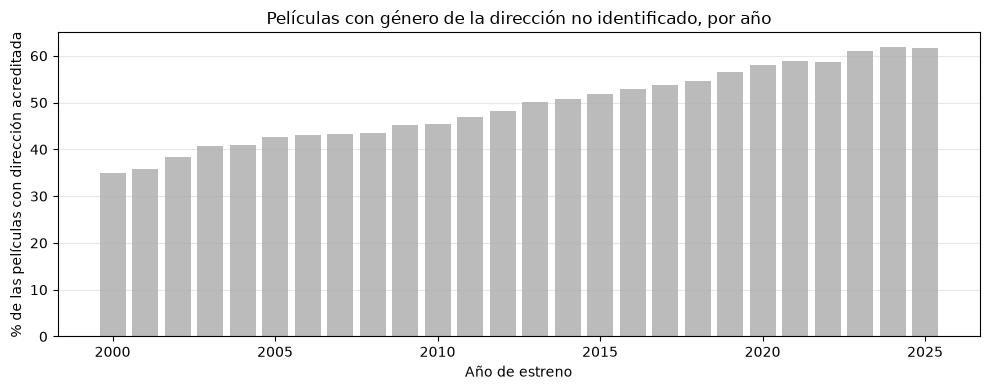

anio_estreno,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
% no identificado,35.0,35.8,38.3,40.8,40.8,42.7,43.2,43.2,43.5,45.1,...,52.9,53.8,54.5,56.5,58.1,58.8,58.7,61.1,61.9,61.7


In [23]:
ni = df.assign(ni=df["grupo_direccion"] == "No identificado").groupby("anio_estreno")["ni"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(ni.index, ni.values, color=COLOR_NEUTRO)
ax.set_title("Películas con género de la dirección no identificado, por año")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("% de las películas con dirección acreditada")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(carpeta_fig / "10_no_identificado_por_anio.png", dpi=200)
plt.show()
display(ni.round(1).to_frame("% no identificado").T)

El porcentaje de películas conservadas cuya dirección tiene género no
identificado crece de forma casi continua: pasa de alrededor del 35 %
en 2000 a alrededor del 62 % en 2024-2025. Por tanto, la base de
películas con dirección de género conocido es proporcionalmente menor
en los años recientes, y el aumento observado en el porcentaje de
mujeres debe interpretarse con cautela. No es posible determinar el
sentido del posible sesgo con estos datos. Que el aumento se mantenga
en los tres niveles de visibilidad y en los cuatro géneros analizados
apoya la tendencia, pero no la confirma de forma definitiva.

## Resumen de resultados

**Hipótesis inicial** (formulada antes de ver los datos): en todos los
géneros hay muchos más hombres que mujeres, su presencia ha aumentado
en los últimos 25 años y el drama es el género que más dirigen las
mujeres.

- **Más hombres en todos los géneros: se confirma.** Ningún género
  supera el 29,6 % de películas con alguna mujer en la dirección
  (documental), por lo que los hombres dirigen al menos el 70 % en todos.
- **Aumento con el tiempo: se confirma.** El porcentaje de películas
  dirigidas por mujeres y personas no binarias pasa del 13,5 %
  (2000-04) al 24,2 % (2021-25), con un aumento de entre 0,47 y 0,54
  puntos por año según el nivel de visibilidad. Frente a los hombres, pasan
  de 15,8 a 32,7 películas por cada 100 dirigidas por hombres: crecen más
  rápido que ellos (×5,8 frente a ×2,8).
- **Drama: se confirma solo en parte.** Es el género más frecuente
  entre las directoras (32,0 %), pero también entre los directores
  (32,8 %), por lo que no las distingue. El género con más presencia
  de mujeres es el documental (26,7 % de sus películas), que pesa un
  27,0 % en la filmografía de ellas frente al 18,3 % en la de ellos.

**Otros resultados.** Acción es el género con menos presencia de
mujeres (3,7 %). El porcentaje global baja del 20,2 % con todas las
películas al 10,7 % con al menos 100 votos. La hipótesis revisada
(menos del 50 % en todos los géneros) se cumple, pero era esperable.

**Cautelas.** Solo se compara la dirección de género conocido: el
53,6 % de las películas conservadas está en «No identificado», y ese
porcentaje crece del 35 % en 2000 al 62 % en 2025. El descarte de
películas sin director no es aleatorio y el género procede de TMDB, no
de una autoidentificación. No se puede determinar el sentido del sesgo
con estos datos, por lo que la tendencia debe interpretarse con
cautela.

In [24]:
# Resultados en CSV pequeños para la memoria
carpeta_res = raiz / "src" / "data" / "resultados"
carpeta_res.mkdir(parents=True, exist_ok=True)

claves = {"Todas las películas": "todas", "Con al menos 1 voto": "1voto",
          "Con al menos 100 votos": "100votos"}
for nombre, r in resultados.items():
    r.round(2).to_csv(carpeta_res / f"presencia_genero_{claves[nombre]}.csv", encoding="utf-8-sig")

pd.concat(series, names=["nivel"]).round(2).to_csv(
    carpeta_res / "evolucion_mujeres.csv", encoding="utf-8-sig")
comp.round(2).to_csv(carpeta_res / "generos_por_grupo.csv", encoding="utf-8-sig")
tabla_periodos.to_csv(carpeta_res / "evolucion_por_genero_periodo.csv", encoding="utf-8-sig")
hm.round(2).to_csv(carpeta_res / "mujeres_frente_a_hombres.csv", encoding="utf-8-sig")
ni.round(2).to_frame("pct_no_identificado").to_csv(
    carpeta_res / "no_identificado_por_anio.csv", encoding="utf-8-sig")
df_todas["grupo_direccion"].value_counts().to_frame("n").to_csv(
    carpeta_res / "grupos_direccion.csv", encoding="utf-8-sig")

print(sorted(p.name for p in carpeta_res.iterdir()))

['evolucion_mujeres.csv', 'evolucion_por_genero_periodo.csv', 'generos_por_grupo.csv', 'grupos_direccion.csv', 'mujeres_frente_a_hombres.csv', 'no_identificado_por_anio.csv', 'presencia_genero_100votos.csv', 'presencia_genero_1voto.csv', 'presencia_genero_todas.csv']
